In [25]:
#15-7-26
#decision trees - ask questions at every level so that it divides the data into 2 parts
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (accuracy_score,confusion_matrix,classification_report,ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier,plot_tree

In [39]:
import os
df=pd.read_csv('train.csv')
df['Age']=df['Age'].fillna(df['Age'].median())
most_common_embarked=df['Embarked'].mode()[0]
df['Embarked']=df['Embarked'].fillna(most_common_embarked)
df['IsFemale']=df['Sex'].map({'female':1,'male':0})
features=['Pclass','Age','Fare','SibSp','Parch','IsFemale']
X=df[features]
y=df['Survived']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)

In [27]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)


In [28]:
model=DecisionTreeClassifier(random_state=42)
model.fit(X_train,y_train)
train_acc=accuracy_score(y_train,model.predict(X_train))
test_acc=accuracy_score(y_test,model.predict(X_test))
tree_depth=model.get_depth()
n_leaves=model.get_n_leaves()

print('Unconstrained Decision Tree results: ')
print(f"Tree Depth :{tree_depth}")
print(f"Number of leaves : {n_leaves}")
print(f"Train_Accuracy: {train_acc*100:.2f}% (perfect memorization)")
print(f"Test Accuracy: {test_acc*100:.2f}%")
print()

Unconstrained Decision Tree results: 
Tree Depth :23
Number of leaves : 161
Train_Accuracy: 98.17% (perfect memorization)
Test Accuracy: 80.45%



Text(0.5, 1.0, 'Shallow Decision Tree (depth=3) Splits')

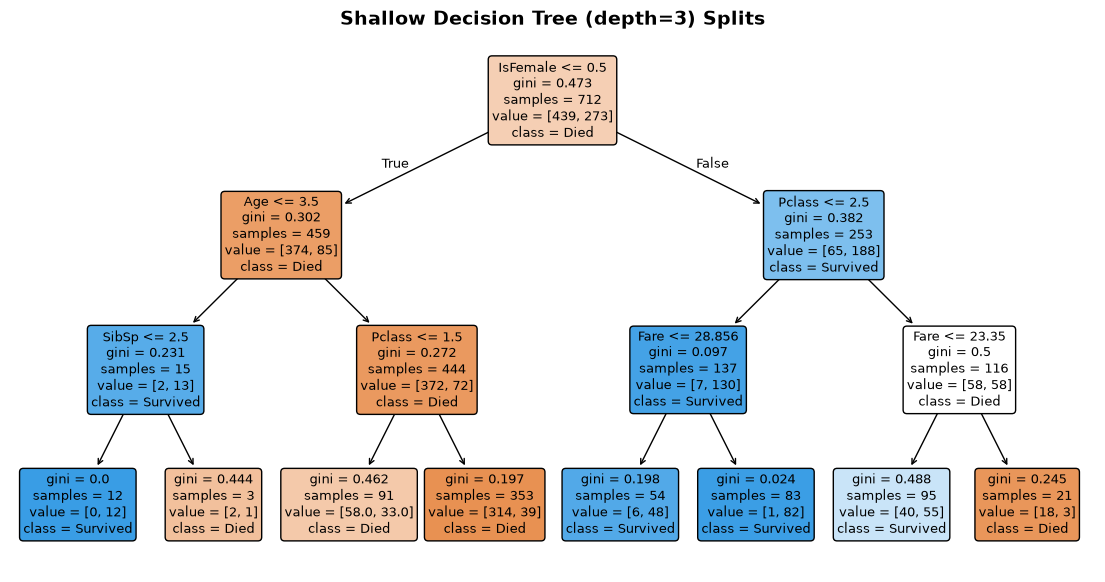

In [29]:
dt_shallow=DecisionTreeClassifier(max_depth=3,random_state=42)
dt_shallow.fit(X_train,y_train)

plt.figure(figsize=(14,7))
plot_tree(
    dt_shallow,
    feature_names=X.columns,
    class_names=['Died','Survived'],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title('Shallow Decision Tree (depth=3) Splits',fontsize=14,fontweight='bold')

Optimal Depth by Test Accuracy: 3 (Accuracy: 81.01%)


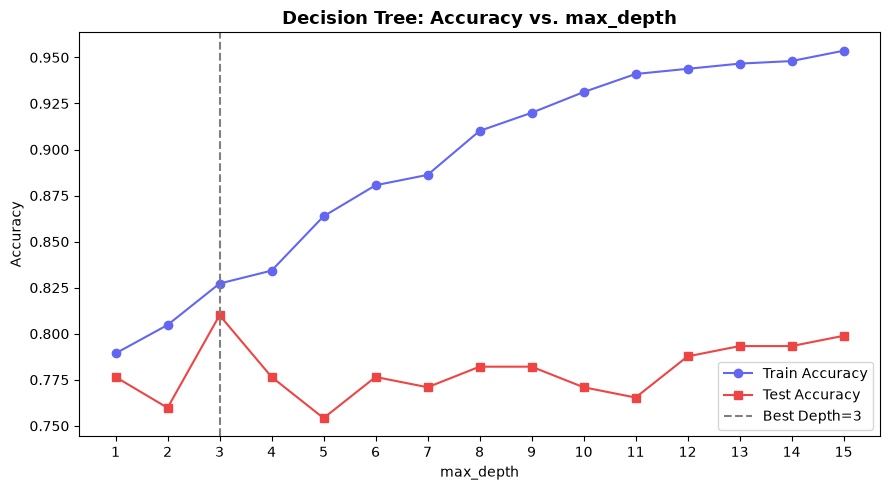

In [30]:
# Hyperparameters tuning
depths=range(1,16)
train_scores=[]
test_scores=[]
for d in depths :
    dt=DecisionTreeClassifier(max_depth=d,random_state=42)
    dt.fit(X_train,y_train)
    train_scores.append(accuracy_score(y_train,dt.predict(X_train)))
    test_scores.append(accuracy_score(y_test,dt.predict(X_test)))
best_depth=depths[np.argmax(test_scores)]
print(f"Optimal Depth by Test Accuracy: {best_depth} (Accuracy: {max(test_scores)*100:.2f}%)")

plt.figure(figsize=(9,5))
plt.plot(depths,train_scores,'o-',color='#6366f1',label='Train Accuracy')
plt.plot(depths,test_scores,'s-',color='#ef4444',label='Test Accuracy')
plt.axvline(best_depth,color='grey',linestyle='--',label=f'Best Depth={best_depth}')
plt.title('Decision Tree: Accuracy vs. max_depth', fontsize=13,fontweight='bold')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.xticks(depths)
plt.legend()
plt.tight_layout()
plt.show()

n_jobs=-1/1/2/-2

In [32]:
#Random Forest
rf=RandomForestClassifier(n_estimators=100,max_depth=5,random_state=42,n_jobs=-1)
rf.fit(X_train,y_train)
y_pred_rf=rf.predict(X_test)
y_prob_rf=rf.predict_proba(X_test)
rf_train_acc=accuracy_score(y_train,rf.predict(X_train))
rf_test_acc=accuracy_score(y_test,y_pred_rf)
rf_cv=cross_val_score(rf,X_train,y_train,cv=5,scoring='accuracy')
print(f"{rf_train_acc*100:.2f}")
print(f"{rf_test_acc*100:.2f}")
print(f"5-fold CV Mean : {rf_cv.mean()*100:.2f}% +- {rf_cv.std()*100:.2f}%")

print("\nrandom Forest classification Report:")
print(classification_report(y_test,y_pred_rf,target_names=['Died','Survived']))

85.81
78.77
5-fold CV Mean : 81.33% +- 2.59%

random Forest classification Report:
              precision    recall  f1-score   support

        Died       0.78      0.91      0.84       110
    Survived       0.80      0.59      0.68        69

    accuracy                           0.79       179
   macro avg       0.79      0.75      0.76       179
weighted avg       0.79      0.79      0.78       179



16-7-26
Thursday DAY-17(19)


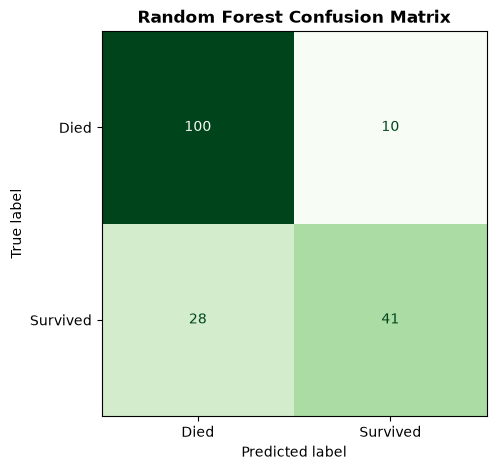

In [34]:
cm_rf=confusion_matrix(y_test,y_pred_rf)
disp=ConfusionMatrixDisplay(confusion_matrix=cm_rf,display_labels=['Died','Survived'])
fig,ax=plt.subplots(figsize=(6,5))
disp.plot(cmap='Greens',ax=ax,colorbar=False)
plt.title('Random Forest Confusion Matrix',fontweight='bold')
plt.grid(False)
plt.show()

                   Model  Test Accuracy  CV Accuracy
0     LogisticRegression       0.804469     0.786556
1  Decision Tree (tuned)       0.810056     0.814705
2           RandomForest       0.787709     0.813287
Classifire Performance Comparison:
                Model  Test Accuracy  CV Accuracy
   LogisticRegression       0.804469     0.786556
Decision Tree (tuned)       0.810056     0.814705
         RandomForest       0.787709     0.813287


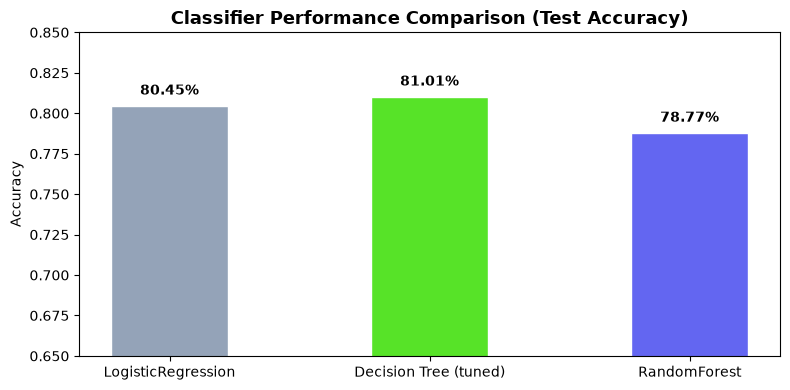

In [38]:
classifiers={
    'LogisticRegression':LogisticRegression(max_iter=1000,
                                            random_state=42).fit(X_train,y_train),
    'Decision Tree (tuned)':DecisionTreeClassifier(max_depth=best_depth,
                                            random_state=42).fit(X_train,y_train),
    'RandomForest':RandomForestClassifier(n_estimators=100,max_depth=5,random_state=42,n_jobs=-1).fit(X_train,y_train)
}
summary=[]
for name,clf in classifiers.items():
    pred=clf.predict(X_test)
    acc=accuracy_score(y_test,pred)
    cv=cross_val_score(clf,X_train,y_train,cv=5,scoring='accuracy').mean()
    summary.append({'Model':name,'Test Accuracy':acc,'CV Accuracy':cv})

summary_df=pd.DataFrame(summary)
print(summary_df)
print('Classifire Performance Comparison:')
print('='*55)
print(summary_df.to_string(index=False))
print('='*55)

plt.figure(figsize=(8,4))
colors=['#94a3b8',"#57e328",'#6366f1']
bars=plt.bar(summary_df['Model'],summary_df['Test Accuracy'],
             color=colors,width=0.45,edgecolor='white')
for bar in bars:
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.005,
             f'{bar.get_height()*100:.2f}%',ha='center',va='bottom',
             fontsize=10,fontweight='bold')
plt.title('Classifier Performance Comparison (Test Accuracy)',fontsize=13,fontweight='bold')
plt.ylabel('Accuracy')
plt.ylim(0.65,0.85)
plt.tight_layout()
plt.show()